In [6]:
import h5py
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.ndimage import label
from skimage import morphology
from skimage import measure
from scipy import ndimage as ndi
from skimage.segmentation import find_boundaries
from scipy.stats import gaussian_kde
from matplotlib.patches import FancyArrowPatch
from scipy.optimize import curve_fit
from scipy.ndimage import map_coordinates
import seaborn as sns
from scipy.ndimage import maximum_filter, label
from scipy.stats import skewnorm
from scipy.stats import lognorm
import fifpy
from scipy.ndimage import gaussian_filter
from scipy.ndimage import label, gaussian_filter
from scipy.stats import lognorm, gaussian_kde
import csv
import os
import csv
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import h5py
from skimage import morphology, measure
from scipy import ndimage as ndi

# shared code and paths (see README.md and shared/)
import sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "shared" / "paths.py").exists())
sys.path.insert(0, str(REPO))
from shared.detection import detect_current_sheets
from shared.fields import partial_x_fft, partial_y_fft
from shared.filtering import iterative_filtering1D, iterative_filtering3D
from shared.stats import avg_beta
from shared.paths import DATA_ROOT, NAS_ROOT, results_dir, cache_dir as shared_cache_dir
RESULTS = results_dir("cs_identification")
CACHE = shared_cache_dir("cs_identification")

In [7]:
#Defining all the required functions

#Fourier Transform Functions


#Defining constants
dx = 0.0625
dy = 0.0625






--- Processing beta = 0.25, t = 200 ---
Loading cached filtered fields...


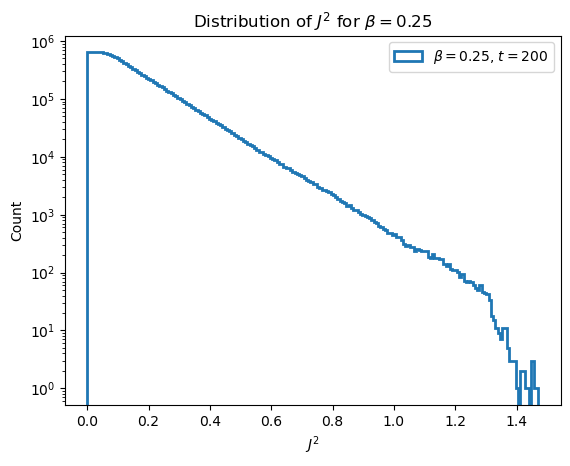

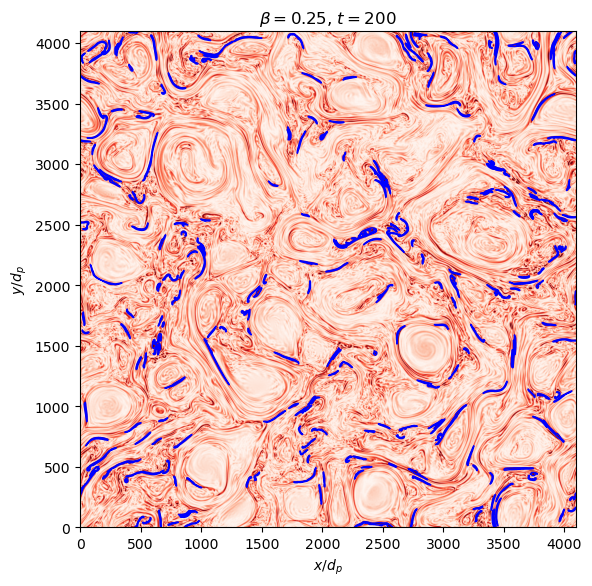

In [7]:
# -----------------------------
# USER SETTINGS
# -----------------------------
beta = 1                  # pick one: 0.0625, 1, or 16
times = [200]             # add more snapshots here, e.g. [100, 150, 200]
cache_dir = str(CACHE / "filtered_cache_Jz")
os.makedirs(cache_dir, exist_ok=True)

# storage (keyed by time)
J2_all = {}
mask_all = {}

# ----- FILTER PARAMETERS (depend on beta) -----
if beta == 0.0625:
    n_iter, Xi = 3, 2.0
elif beta == 0.25:
    n_iter, Xi = 3, 2.3
elif beta == 1:
    n_iter, Xi = 3, 2.5
elif beta == 4:
    n_iter, Xi = 3, 2.7
else:
    n_iter, Xi = 3, 3.0

base_path = f'{DATA_ROOT}/beta_p_{beta}/beta_e_1/'

# -----------------------------
# MAIN LOOP (over times only)
# -----------------------------
for time in times:
    print(f"\n--- Processing beta = {beta}, t = {time} ---")

    File_Bx = base_path + f'Bx_ApJ_t{time}.h5'
    File_By = base_path + f'By_ApJ_t{time}.h5'
    File_Bz = base_path + f'Bz_ApJ_t{time}.h5'

    with h5py.File(File_Bx, 'r') as fBx, \
         h5py.File(File_By, 'r') as fBy, \
         h5py.File(File_Bz, 'r') as fBz:
        data_Bx = fBx['DS1'][:].T
        data_By = fBy['DS1'][:].T
        data_Bz = fBz['DS1'][:].T

    cache_file = f"{cache_dir}/filtered_beta_{beta}_t{time}_iter{n_iter}_Xi{Xi}.npz"

    if os.path.exists(cache_file):
        print("Loading cached filtered fields...")
        data = np.load(cache_file)
        data_Bx_f = data['Bx']
        data_By_f = data['By']
        data_Bz_f = data['Bz']
    else:
        print("Computing filtering (slow)...")
        data_Bx_f, data_By_f, data_Bz_f = iterative_filtering3D(
            data_Bx, data_By, data_Bz, n_iter, Xi=Xi
        )
        np.savez_compressed(
            cache_file, Bx=data_Bx_f, By=data_By_f, Bz=data_Bz_f
        )

    # ----- CURRENT DENSITY -----
    Jx = partial_y_fft(data_Bz_f, dx)
    Jy = -partial_x_fft(data_Bz_f, dy)
    Jz = partial_x_fft(data_By_f, dy) - partial_y_fft(data_Bx_f, dx)
    # J2 = Jx**2 + Jy**2 + Jz**2
    J2 = np.abs(Jz)

    plt.hist(J2.ravel(), bins=200, log=True,
             histtype='step', linewidth=2,
             label=fr'$\beta = {beta}$, $t = {time}$')

    # ----- CURRENT SHEET DETECTION -----
    sheets = detect_current_sheets(J2)
    mask = np.zeros_like(J2)
    for sheet in sheets:
        for (i, j) in sheet:
            mask[i, j] = 1

    # ----- MORPHOLOGICAL CLEANING -----
    struct = morphology.disk(1)
    mask = morphology.binary_opening(mask, struct)
    mask = morphology.binary_closing(mask, struct)
    mask = morphology.remove_small_objects(
        mask.astype(bool), min_size=500
    ).astype(int)

    J2_all[time] = J2
    mask_all[time] = mask

plt.legend()
plt.xlabel(r'$J^2$')
plt.ylabel('Count')
plt.title(fr'Distribution of $J^2$ for $\beta = {beta}$')
plt.show()

# -----------------------------
# COLOR SCALE
# -----------------------------
all_values = np.concatenate([v.ravel() for v in J2_all.values()])
vmax_global = np.percentile(all_values, 99)

# -----------------------------
# PLOT (one row of panels, one per time)
# -----------------------------
fig, axes = plt.subplots(
    1, len(times),
    figsize=(6 * len(times), 6),
    squeeze=False
)

for c, time in enumerate(times):
    ax = axes[0][c]
    im = ax.imshow(
        J2_all[time].T, cmap='Reds', origin='lower', vmax=vmax_global
    )
    ax.contour(
        mask_all[time].T, levels=[0.5], colors='blue', linewidths=1
    )
    ax.set_title(fr'$\beta = {beta}$, $t = {time}$')
    ax.set_xlabel(r'$x/d_p$')
    ax.set_ylabel(r'$y/d_p$')

plt.tight_layout()
plt.savefig(RESULTS / f"J2_comparison_beta_{beta}.png", dpi=300)
plt.show()

Loading cached filtered B ...
beta_field:  median = 0.9604,  mean = 0.9825,  5-95% = [0.7174, 1.3248]
(nominal beta_p = 1; if the median is off by a constant factor, that factor is the pressure normalisation)


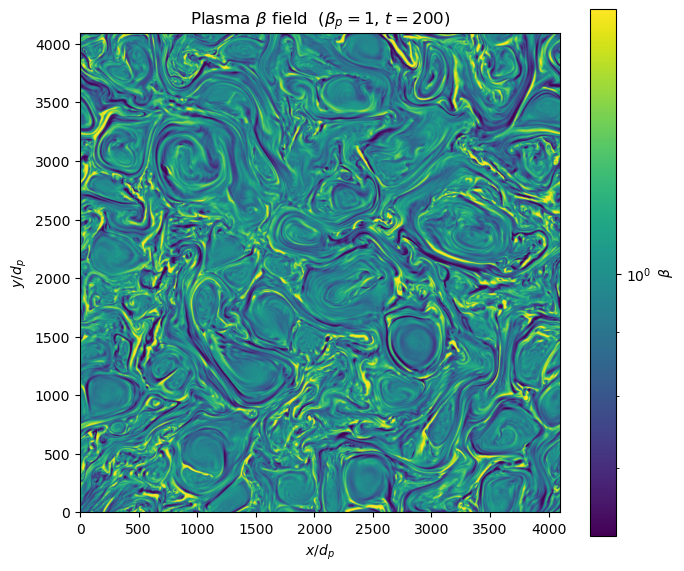

In [1]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# -----------------------------
# SETTINGS
# -----------------------------
beta = 1
time = 200
sim_tag = "ApJ"
base_path = f"{DATA_ROOT}/beta_p_{beta}/beta_e_1/"

cache_dir = str(CACHE / "filtered_cache_Jz")          # same cache your detection uses
os.makedirs(cache_dir, exist_ok=True)


def load(tag):
    with h5py.File(f"{base_path}{tag}_{sim_tag}_t{time}.h5", "r") as f:
        return f["DS1"][:].T


if beta == 0.0625:
    n_iter, Xi = 3, 2.0
elif beta == 0.25:
    n_iter, Xi = 3, 2.3
elif beta == 1:
    n_iter, Xi = 3, 2.5
elif beta == 4:
    n_iter, Xi = 3, 2.7
else:
    n_iter, Xi = 3, 3.0

dx = dy = 0.0625

# -----------------------------
# Filtered B  (cached; reused across all your scripts)
# -----------------------------
cache_file = f"{cache_dir}/filtered_beta_{beta}_t{time}_iter{n_iter}_Xi{Xi}.npz"
if os.path.exists(cache_file):
    print("Loading cached filtered B ...")
    d = np.load(cache_file)
    Bx_f, By_f, Bz_f = d["Bx"], d["By"], d["Bz"]
else:
    print("Filtering B (slow) ...")
    Bx_f, By_f, Bz_f = iterative_filtering3D(load("Bx"), load("By"), load("Bz"), n_iter, Xi=Xi)
    np.savez_compressed(cache_file, Bx=Bx_f, By=By_f, Bz=Bz_f)

# -----------------------------
# Magnetic pressure  =  |B|^2 / 2
# -----------------------------
P_mag = 0.5 * (Bx_f**2 + By_f**2 + Bz_f**2)

# -----------------------------
# Thermal (scalar) pressure from gyrotropic components:
#   trace(P) = P_par + 2 P_perp   ->   P_scalar = (P_par + 2 P_perp) / 3
# ADJUST the two tags below to match your files.
# -----------------------------
P_par  = load("Ppar1")
P_perp = load("Pper1")
P_scalar = (P_par + 2.0 * P_perp) / 3.0

# -----------------------------
# Plasma beta field
# -----------------------------
beta_field = P_scalar / P_mag

# -----------------------------
# Sanity check: the domain median should be ~ nominal beta_p
# -----------------------------
print(f"beta_field:  median = {np.median(beta_field):.4f},  "
      f"mean = {np.mean(beta_field):.4f},  "
      f"5-95% = [{np.percentile(beta_field, 5):.4f}, {np.percentile(beta_field, 95):.4f}]")
print(f"(nominal beta_p = {beta}; if the median is off by a constant factor, "
      f"that factor is the pressure normalisation)")

# -----------------------------
# Map
# -----------------------------
plt.figure(figsize=(7, 6))
im = plt.imshow(beta_field.T, origin="lower", cmap="viridis",
                norm=LogNorm(vmin=np.percentile(beta_field, 1),
                             vmax=np.percentile(beta_field, 99)))
plt.colorbar(im, label=r"$\beta$")
plt.xlabel(r"$x/d_p$"); plt.ylabel(r"$y/d_p$")
plt.title(rf"Plasma $\beta$ field  ($\beta_p = {beta}$, $t = {time}$)")
plt.tight_layout()
plt.savefig(RESULTS / f"beta_field_beta{beta}_t{time}.png", dpi=300)
plt.show()

beta_field median = 0.960  (nominal beta_p = 1)
found 244 current sheets
measured 244 sheets that had a usable ring


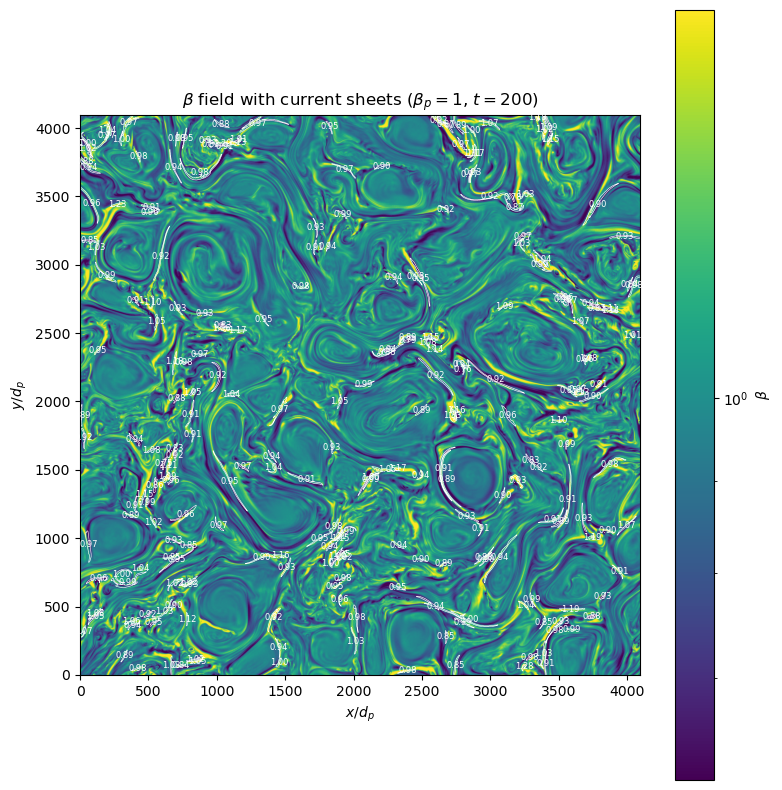

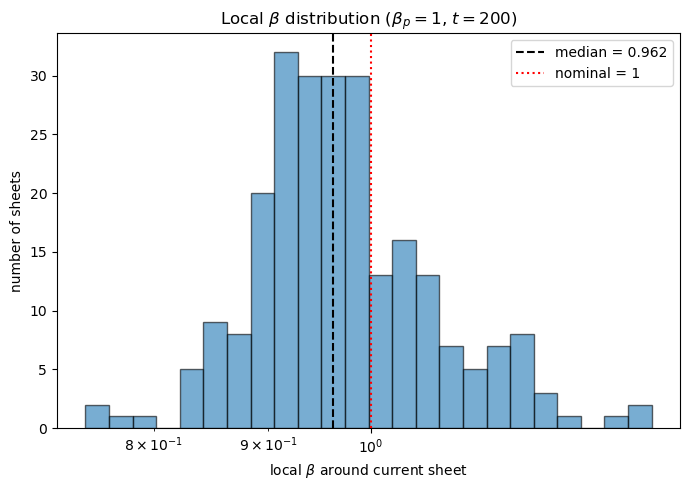


--- thickness statistics in beta bins ---
          beta range     N   median thick (d_i)   mean thick (d_i)
  0.746-  0.862    18                0.673              0.718
  0.862-  0.998   150                0.707              0.733
  0.998-  1.154    61                0.729              0.755
  1.154-  1.335    14                0.729              0.749


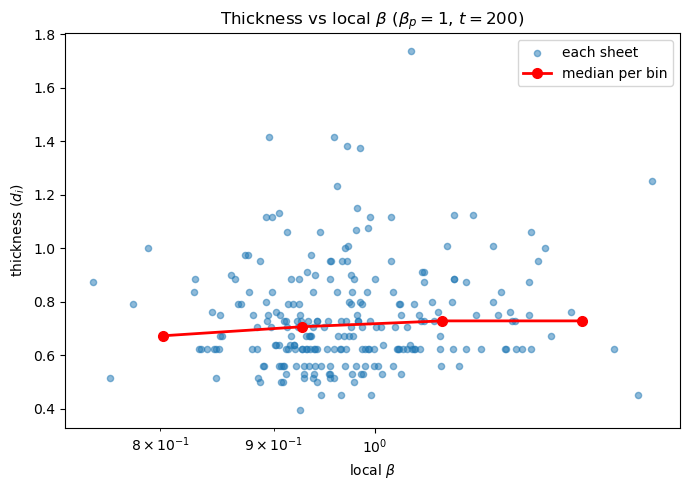


--- overall statistics ---
local beta : median = 0.962, mean = 0.976
thickness  : median = 0.707, mean = 0.741 d_i

Everything saved in:  cs_beta_analysis_beta1_t200/


In [3]:
# ============================================================
#  Current sheets:  local beta around each sheet  +  thickness
#  ------------------------------------------------------------
#  For ONE simulation snapshot this script:
#    1. builds the plasma-beta field
#    2. detects the current sheets (your method)
#    3. for each sheet: measures thickness and the local beta in a ring around it
#    4. saves a histogram of local beta
#    5. saves a picture of every sheet (with its beta printed)
#    6. saves a table + scatter plot of beta vs thickness
#  Everything is written into one output folder.
# ============================================================

import os
import csv
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import h5py
from skimage import morphology, measure
from scipy import ndimage as ndi

# -----------------------------
# SETTINGS  (change these)
# -----------------------------
beta     = 1                 # which run: 0.0625, 0.25, 1, 4, 16
time     = 200               # which snapshot
sim_tag  = "ApJ"
base_path = f"{DATA_ROOT}/beta_p_{beta}/beta_e_1/"

cache_dir = str(CACHE / "filtered_cache_Jz")
out_dir   = str(RESULTS / f"cs_beta_analysis_beta{beta}_t{time}")   # all results go here

px_per_di = 16.0             # pixels per ion inertial length (turns thickness into d_i)
box_pad   = 5                # padding (px) added around the sheet to make the rectangle
SAVE_SHEET_PICTURES = False   # set False if you don't want one image per sheet

os.makedirs(cache_dir, exist_ok=True)
os.makedirs(out_dir, exist_ok=True)
os.makedirs(f"{out_dir}/sheets", exist_ok=True)

# filter parameters for this beta (same table as your detection)
if beta == 0.0625:
    n_iter, Xi = 3, 2.0
elif beta == 0.25:
    n_iter, Xi = 3, 2.3
elif beta == 1:
    n_iter, Xi = 3, 2.5
elif beta == 4:
    n_iter, Xi = 3, 2.7
else:
    n_iter, Xi = 3, 3.0

dx = dy = 0.0625


# ============================================================
# STEP 1.  Plasma beta field  (uses RAW fields, no filtering)
#          beta = thermal pressure / magnetic pressure = P / (|B|^2 / 2)
# ============================================================
Bx, By, Bz = load("Bx"), load("By"), load("Bz")
P_mag = 0.5 * (Bx**2 + By**2 + Bz**2)             # magnetic pressure

# scalar pressure from the gyrotropic tensor:  trace = P_par + 2 P_perp
P_par  = load("Ppar1")                             # <-- adjust tag if needed
P_perp = load("Pper1")                            # <-- adjust tag if needed
P_scalar = (P_par + 2.0 * P_perp) / 3.0

beta_field = P_scalar / P_mag                     # beta at every grid point

print(f"beta_field median = {np.median(beta_field):.3f}  (nominal beta_p = {beta})")

# one colour scale (log) reused for all the beta pictures
beta_norm = LogNorm(vmin=np.percentile(beta_field, 1),
                    vmax=np.percentile(beta_field, 99))


# ============================================================
# STEP 2.  Detect the current sheets  (your method)
# ============================================================
# filter the magnetic field (cached so it is only computed once)
cache_file = f"{cache_dir}/filtered_beta_{beta}_t{time}_iter{n_iter}_Xi{Xi}.npz"
if os.path.exists(cache_file):
    d = np.load(cache_file)
    Bx_f, By_f, Bz_f = d["Bx"], d["By"], d["Bz"]
else:
    Bx_f, By_f, Bz_f = iterative_filtering3D(Bx, By, Bz, n_iter, Xi=Xi)
    np.savez_compressed(cache_file, Bx=Bx_f, By=By_f, Bz=Bz_f)

# out-of-plane current and |Jz|
Jz = partial_x_fft(By_f, dy) - partial_y_fft(Bx_f, dx)
J2 = np.abs(Jz)

# detection + cleaning (exactly your steps)
sheets = detect_current_sheets(J2)
mask = np.zeros_like(J2)
for sheet in sheets:
    for (i, j) in sheet:
        mask[i, j] = 1
struct = morphology.disk(1)
mask = morphology.binary_opening(mask, struct)
mask = morphology.binary_closing(mask, struct)
mask = morphology.remove_small_objects(mask.astype(bool), min_size=500).astype(int)

# give each separate sheet its own number (1, 2, 3, ...)
labeled = measure.label(mask, connectivity=2)
n_sheets = labeled.max()
all_sheets_mask = labeled > 0          # every sheet, used to exclude cores from rings
print(f"found {n_sheets} current sheets")


# ============================================================
# STEP 3.  For each sheet: thickness + local beta in a ring around it
# ============================================================
sheet_id   = []     # sheet number
thickness  = []     # thickness in d_i
local_beta = []     # median beta in the ring around the sheet

for k in range(1, n_sheets + 1):
    region = (labeled == k)                       # this sheet's pixels

    # --- thickness: largest circle that fits inside the sheet ---
    # distance transform gives each pixel's distance to the edge; max * 2 = thickness
    dist = ndi.distance_transform_edt(region)
    thick_di = (2 * dist.max()) / px_per_di

    # --- local beta: a RECTANGLE around the sheet, with all sheet cores removed ---
    # take the sheet's bounding box, grow it by box_pad on every side, then drop
    # any pixel that belongs to a sheet, so we measure the plasma AROUND the sheet.
    xs_r, ys_r = np.where(region)
    bx0 = max(0, xs_r.min() - box_pad)
    bx1 = min(beta_field.shape[0], xs_r.max() + box_pad + 1)
    by0 = max(0, ys_r.min() - box_pad)
    by1 = min(beta_field.shape[1], ys_r.max() + box_pad + 1)
    box_region = np.zeros_like(region)
    box_region[bx0:bx1, by0:by1] = True
    box_region = box_region & ~all_sheets_mask
    if box_region.sum() < 20:                     # almost no surrounding pixels -> skip
        continue
    beta_here = float(np.median(beta_field[box_region]))

    sheet_id.append(k)
    thickness.append(thick_di)
    local_beta.append(beta_here)

    # --- save a picture of this sheet with its local beta ---
    if SAVE_SHEET_PICTURES:
        pad = box_pad + 10                        # show a little extra around the rectangle
        x0, x1 = max(0, xs_r.min() - pad), min(beta_field.shape[0], xs_r.max() + pad + 1)
        y0, y1 = max(0, ys_r.min() - pad), min(beta_field.shape[1], ys_r.max() + pad + 1)
        crop_beta   = beta_field[x0:x1, y0:y1]
        crop_region = region[x0:x1, y0:y1]
        crop_box    = box_region[x0:x1, y0:y1]
        ext = [x0, x1, y0, y1]

        plt.figure(figsize=(6, 5))
        plt.imshow(crop_beta.T, origin="lower", extent=ext, cmap="viridis", norm=beta_norm)
        plt.colorbar(label=r"$\beta$")
        plt.contour(crop_region.T, levels=[0.5], colors="white", linewidths=1.5, extent=ext)  # the sheet
        plt.contour(crop_box.T,    levels=[0.5], colors="cyan",  linewidths=0.8, extent=ext)  # the rectangle
        plt.xlabel(r"$x/d_p$"); plt.ylabel(r"$y/d_p$")
        plt.title(f"sheet {k}:  thickness = {thick_di:.2f} $d_i$,  local "
                  + rf"$\beta$ = {beta_here:.3f}")
        plt.tight_layout()
        plt.savefig(f"{out_dir}/sheets/sheet_{k:03d}.png", dpi=130)
        plt.close()

# turn the lists into arrays for convenience
sheet_id   = np.array(sheet_id)
thickness  = np.array(thickness)
local_beta = np.array(local_beta)
print(f"measured {len(sheet_id)} sheets that had a usable ring")

if len(local_beta) == 0:
    raise SystemExit("No sheets with a usable ring were found.")


# ============================================================
# STEP 4.  Overview picture: beta map + sheets, each labelled with its beta
# ============================================================
plt.figure(figsize=(8, 8))
plt.imshow(beta_field.T, origin="lower", cmap="viridis", norm=beta_norm)
plt.colorbar(label=r"$\beta$")
plt.contour(all_sheets_mask.T, levels=[0.5], colors="white", linewidths=0.4)
for i in range(len(sheet_id)):
    xr, yr = np.where(labeled == sheet_id[i])
    plt.text(xr.mean(), yr.mean(), f"{local_beta[i]:.2f}",
             color="white", fontsize=6, ha="center", va="center")
plt.xlabel(r"$x/d_p$"); plt.ylabel(r"$y/d_p$")
plt.title(rf"$\beta$ field with current sheets ($\beta_p={beta}$, $t={time}$)")
plt.tight_layout()
plt.savefig(f"{out_dir}/overview_beta_with_sheets.png", dpi=300)
plt.show()


# ============================================================
# STEP 5.  Histogram of the local beta around the sheets
# ============================================================
plt.figure(figsize=(7, 5))
plt.hist(local_beta,
         bins=np.logspace(np.log10(local_beta.min()), np.log10(local_beta.max()), 25),
         alpha=0.6, edgecolor="black")
plt.axvline(np.median(local_beta), color="black", linestyle="--",
            label=f"median = {np.median(local_beta):.3f}")
plt.axvline(beta, color="red", linestyle=":", label=f"nominal = {beta}")
plt.xscale("log")
plt.xlabel(r"local $\beta$ around current sheet")
plt.ylabel("number of sheets")
plt.title(rf"Local $\beta$ distribution ($\beta_p={beta}$, $t={time}$)")
plt.legend()
plt.tight_layout()
plt.savefig(f"{out_dir}/histogram_local_beta.png", dpi=300)
plt.show()


# ============================================================
# STEP 6.  beta vs thickness:  per-sheet table, summary table, scatter plot
# ============================================================
# 6a. per-sheet table
with open(f"{out_dir}/beta_vs_thickness.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["sheet_id", "thickness_di", "local_beta"])
    for i in range(len(sheet_id)):
        w.writerow([int(sheet_id[i]), thickness[i], local_beta[i]])

# 6b. summary table: split sheets into beta bins and look at the thickness in each
bin_edges = np.logspace(np.log10(local_beta.min()), np.log10(local_beta.max()), 5)  # 4 bins
print("\n--- thickness statistics in beta bins ---")
print(f"{'beta range':>20} {'N':>5} {'median thick (d_i)':>20} {'mean thick (d_i)':>18}")
summary_rows = []
bin_centres, bin_med_thick = [], []
for i in range(len(bin_edges) - 1):
    lo, hi = bin_edges[i], bin_edges[i + 1]
    sel = (local_beta >= lo) & (local_beta < hi)
    if sel.sum() == 0:
        continue
    med_t  = np.median(thickness[sel])
    mean_t = np.mean(thickness[sel])
    print(f"{lo:7.3f}-{hi:7.3f} {sel.sum():>5} {med_t:>20.3f} {mean_t:>18.3f}")
    summary_rows.append([lo, hi, int(sel.sum()), med_t, mean_t])
    bin_centres.append(np.sqrt(lo * hi))   # geometric centre (log axis)
    bin_med_thick.append(med_t)

with open(f"{out_dir}/beta_thickness_summary.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["beta_lo", "beta_hi", "n_sheets", "median_thickness_di", "mean_thickness_di"])
    w.writerows(summary_rows)

# 6c. scatter plot of thickness vs local beta, with the binned medians on top
plt.figure(figsize=(7, 5))
plt.scatter(local_beta, thickness, s=20, alpha=0.5, label="each sheet")
plt.plot(bin_centres, bin_med_thick, "o-", color="red", lw=2, ms=7, label="median per bin")
plt.xscale("log")
plt.xlabel(r"local $\beta$")
plt.ylabel(r"thickness $(d_i)$")
plt.title(rf"Thickness vs local $\beta$ ($\beta_p={beta}$, $t={time}$)")
plt.legend()
plt.tight_layout()
plt.savefig(f"{out_dir}/thickness_vs_beta.png", dpi=300)
plt.show()

# ---- final quick numbers ----
print("\n--- overall statistics ---")
print(f"local beta : median = {np.median(local_beta):.3f}, mean = {np.mean(local_beta):.3f}")
print(f"thickness  : median = {np.median(thickness):.3f}, mean = {np.mean(thickness):.3f} d_i")
print(f"\nEverything saved in:  {out_dir}/")

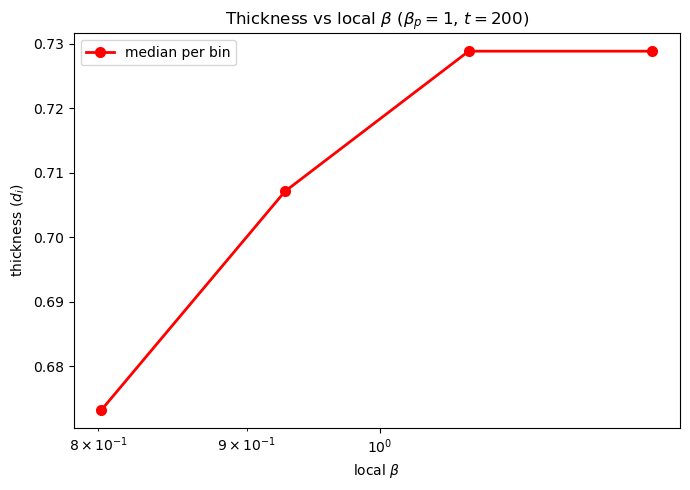

In [5]:
plt.figure(figsize=(7, 5))
# plt.scatter(local_beta, thickness, s=20, alpha=0.5, label="each sheet")
plt.plot(bin_centres, bin_med_thick, "o-", color="red", lw=2, ms=7, label="median per bin")
plt.xscale("log")
plt.xlabel(r"local $\beta$")
plt.ylabel(r"thickness $(d_i)$")
plt.title(rf"Thickness vs local $\beta$ ($\beta_p={beta}$, $t={time}$)")
plt.legend()
plt.tight_layout()
plt.savefig(f"{out_dir}/thickness_vs_beta.png", dpi=300)
plt.show()

Loading cached filtered B ...
domain average beta = 2<P>/<B^2> = 0.9618  (nominal beta_p = 1)
(if this is off by a constant factor, that factor is the pressure normalisation)
found 244 current sheets
measured 244 sheets that had a usable rectangle


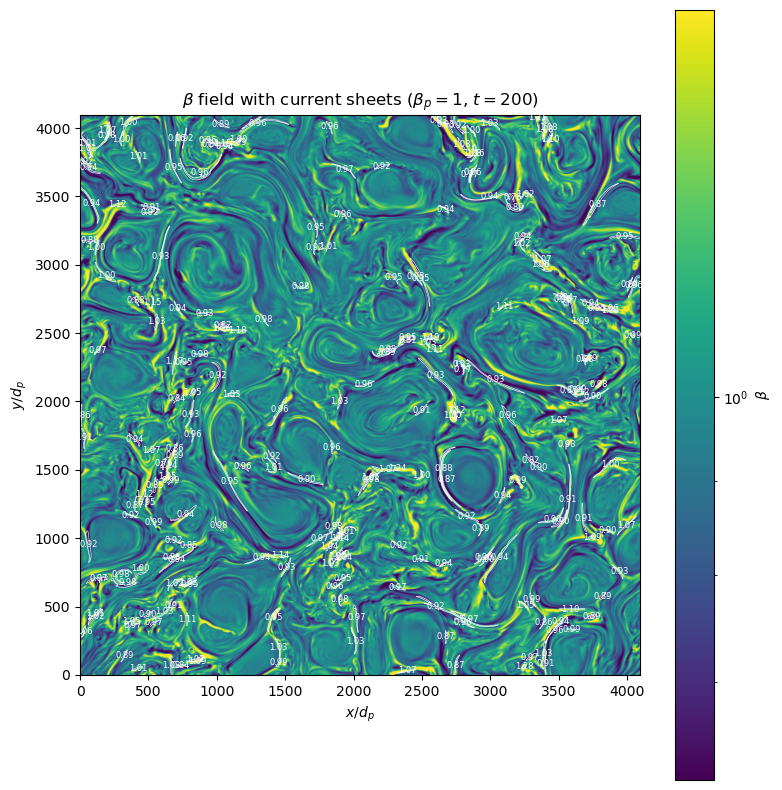

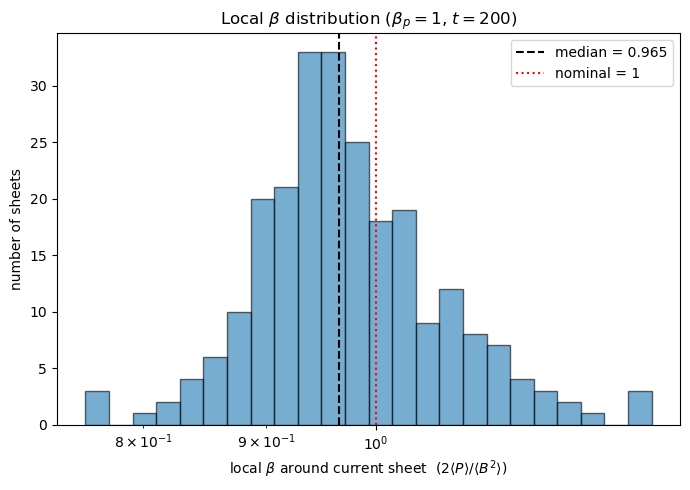


--- thickness statistics in beta bins ---
          beta range     N   median thick (d_i)   mean thick (d_i)
  0.757-  0.867    16                0.755              0.729
  0.867-  0.993   142                0.673              0.730
  0.993-  1.137    73                0.729              0.756
  1.137-  1.302    12                0.701              0.744


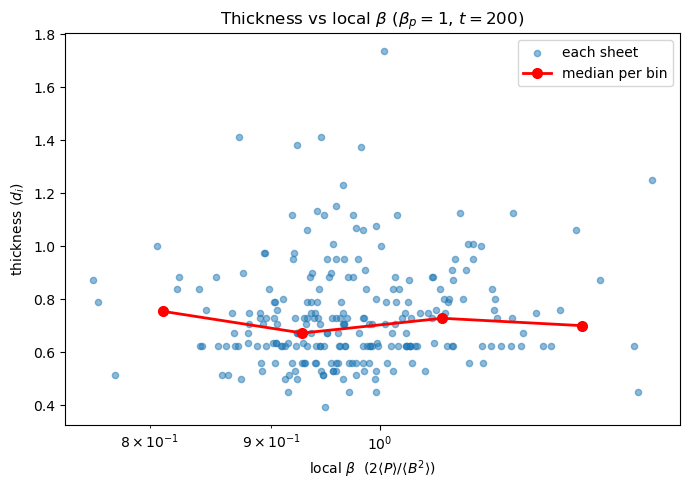


--- overall statistics ---
local beta : median = 0.965, mean = 0.978
thickness  : median = 0.707, mean = 0.741 d_i

Everything saved in:  cs_beta_analysis_beta1_t200/


In [8]:
# ============================================================
#  Current sheets:  local beta around each sheet  +  thickness
#  ------------------------------------------------------------
#  For ONE simulation snapshot this script:
#    1. builds the plasma-beta field (from FILTERED B; cached)
#    2. detects the current sheets (your method)
#    3. for each sheet: measures thickness and the local beta in a rectangle
#       around it, where local beta = 2<P>/<B^2> (ratio of averages)
#    4. saves a histogram of local beta
#    5. saves a picture of every sheet (with its beta printed)
#    6. saves a table + scatter plot of beta vs thickness
# ============================================================

# -----------------------------
# SETTINGS  (change these)
# -----------------------------
beta     = 1                 # which run: 0.0625, 0.25, 1, 4, 16
time     = 200               # which snapshot
sim_tag  = "ApJ"
base_path = f"{DATA_ROOT}/beta_p_{beta}/beta_e_1/"

cache_dir = str(CACHE / "filtered_cache_Jz")
out_dir   = str(RESULTS / f"cs_beta_analysis_beta{beta}_t{time}")   # all results go here

px_per_di = 16.0             # pixels per ion inertial length (turns thickness into d_i)
box_pad   = 5                # padding (px) added around the sheet to make the rectangle
SAVE_SHEET_PICTURES = True   # set False if you don't want one image per sheet

os.makedirs(cache_dir, exist_ok=True)
os.makedirs(out_dir, exist_ok=True)
os.makedirs(f"{out_dir}/sheets", exist_ok=True)

# filter parameters for this beta (same table as your detection)
if beta == 0.0625:
    n_iter, Xi = 3, 2.0
elif beta == 0.25:
    n_iter, Xi = 3, 2.3
elif beta == 1:
    n_iter, Xi = 3, 2.5
elif beta == 4:
    n_iter, Xi = 3, 2.7
else:
    n_iter, Xi = 3, 3.0

dx = dy = 0.0625


# ============================================================
# STEP 0.  Filtered B  (cached; reused across your scripts)
#          raw fields are only read on a cache miss
# ============================================================
cache_file = f"{cache_dir}/filtered_beta_{beta}_t{time}_iter{n_iter}_Xi{Xi}.npz"
if os.path.exists(cache_file):
    print("Loading cached filtered B ...")
    d = np.load(cache_file)
    Bx_f, By_f, Bz_f = d["Bx"], d["By"], d["Bz"]
else:
    print("Filtering B (slow) ...")
    Bx_f, By_f, Bz_f = iterative_filtering3D(load("Bx"), load("By"), load("Bz"), n_iter, Xi=Xi)
    np.savez_compressed(cache_file, Bx=Bx_f, By=By_f, Bz=Bz_f)


# ============================================================
# STEP 1.  Plasma beta field  (from FILTERED B)
#   - pointwise field  beta_field = P / (|B|^2 / 2)   -> used only for the MAP
#   - "average beta" over any region = 2<P>/<B^2>     -> used for the reported numbers
# ============================================================
B2    = Bx_f**2 + By_f**2 + Bz_f**2                 # |B|^2  (filtered)
P_mag = 0.5 * B2                                    # magnetic pressure

# scalar pressure from the gyrotropic tensor:  trace = P_par + 2 P_perp
P_par  = load("Ppar1")                             # <-- adjust tag if needed
P_perp = load("Pper1")                            # <-- adjust tag if needed
P_scalar = (P_par + 2.0 * P_perp) / 3.0

beta_field = P_scalar / P_mag                     # pointwise beta (for the colour map only)


# domain calibration: this is the definition that should match nominal beta_p
beta_domain = 2.0 * P_scalar.mean() / B2.mean()
print(f"domain average beta = 2<P>/<B^2> = {beta_domain:.4f}  (nominal beta_p = {beta})")
print("(if this is off by a constant factor, that factor is the pressure normalisation)")

# one colour scale (log) reused for all the beta pictures
beta_norm = LogNorm(vmin=np.percentile(beta_field, 1),
                    vmax=np.percentile(beta_field, 99))


# ============================================================
# STEP 2.  Detect the current sheets  (your method; B already filtered above)
# ============================================================
# out-of-plane current and |Jz|
Jz = partial_x_fft(By_f, dy) - partial_y_fft(Bx_f, dx)
J2 = np.abs(Jz)

# detection + cleaning (exactly your steps)
sheets = detect_current_sheets(J2)
mask = np.zeros_like(J2)
for sheet in sheets:
    for (i, j) in sheet:
        mask[i, j] = 1
struct = morphology.disk(1)
mask = morphology.binary_opening(mask, struct)
mask = morphology.binary_closing(mask, struct)
mask = morphology.remove_small_objects(mask.astype(bool), min_size=500).astype(int)

# give each separate sheet its own number (1, 2, 3, ...)
labeled = measure.label(mask, connectivity=2)
n_sheets = labeled.max()
all_sheets_mask = labeled > 0          # every sheet, used to exclude cores from rectangles
print(f"found {n_sheets} current sheets")


# ============================================================
# STEP 3.  For each sheet: thickness + local beta (= 2<P>/<B^2>) around it
# ============================================================
sheet_id   = []     # sheet number
thickness  = []     # thickness in d_i
local_beta = []     # 2<P>/<B^2> in the rectangle around the sheet

for k in range(1, n_sheets + 1):
    region = (labeled == k)                       # this sheet's pixels

    # --- thickness: largest circle that fits inside the sheet ---
    dist = ndi.distance_transform_edt(region)
    thick_di = (2 * dist.max()) / px_per_di

    # --- local beta: a RECTANGLE around the sheet, with all sheet cores removed ---
    xs_r, ys_r = np.where(region)
    bx0 = max(0, xs_r.min() - box_pad)
    bx1 = min(beta_field.shape[0], xs_r.max() + box_pad + 1)
    by0 = max(0, ys_r.min() - box_pad)
    by1 = min(beta_field.shape[1], ys_r.max() + box_pad + 1)
    box_region = np.zeros_like(region)
    box_region[bx0:bx1, by0:by1] = True
    box_region = box_region & ~all_sheets_mask
    if box_region.sum() < 20:                     # almost no surrounding pixels -> skip
        continue
    beta_here = avg_beta(box_region, P_scalar, B2)              # 2<P>/<B^2> over the surrounding plasma

    sheet_id.append(k)
    thickness.append(thick_di)
    local_beta.append(beta_here)

    # --- save a picture of this sheet with its local beta ---
    if SAVE_SHEET_PICTURES:
        pad = box_pad + 10                        # show a little extra around the rectangle
        x0, x1 = max(0, xs_r.min() - pad), min(beta_field.shape[0], xs_r.max() + pad + 1)
        y0, y1 = max(0, ys_r.min() - pad), min(beta_field.shape[1], ys_r.max() + pad + 1)
        crop_beta   = beta_field[x0:x1, y0:y1]
        crop_region = region[x0:x1, y0:y1]
        crop_box    = box_region[x0:x1, y0:y1]
        ext = [x0, x1, y0, y1]

        plt.figure(figsize=(6, 5))
        plt.imshow(crop_beta.T, origin="lower", extent=ext, cmap="viridis", norm=beta_norm)
        plt.colorbar(label=r"$\beta$")
        plt.contour(crop_region.T, levels=[0.5], colors="white", linewidths=1.5, extent=ext)  # the sheet
        plt.contour(crop_box.T,    levels=[0.5], colors="cyan",  linewidths=0.8, extent=ext)  # the rectangle
        plt.xlabel(r"$x/d_p$"); plt.ylabel(r"$y/d_p$")
        plt.title(f"sheet {k}:  thickness = {thick_di:.2f} $d_i$,  local "
                  + rf"$\beta$ = {beta_here:.3f}")
        plt.tight_layout()
        plt.savefig(f"{out_dir}/sheets/sheet_{k:03d}.png", dpi=130)
        plt.close()

# turn the lists into arrays for convenience
sheet_id   = np.array(sheet_id)
thickness  = np.array(thickness)
local_beta = np.array(local_beta)
print(f"measured {len(sheet_id)} sheets that had a usable rectangle")

if len(local_beta) == 0:
    raise SystemExit("No sheets with a usable rectangle were found.")


# ============================================================
# STEP 4.  Overview picture: beta map + sheets, each labelled with its beta
# ============================================================
plt.figure(figsize=(8, 8))
plt.imshow(beta_field.T, origin="lower", cmap="viridis", norm=beta_norm)
plt.colorbar(label=r"$\beta$")
plt.contour(all_sheets_mask.T, levels=[0.5], colors="white", linewidths=0.4)
for i in range(len(sheet_id)):
    xr, yr = np.where(labeled == sheet_id[i])
    plt.text(xr.mean(), yr.mean(), f"{local_beta[i]:.2f}",
             color="white", fontsize=6, ha="center", va="center")
plt.xlabel(r"$x/d_p$"); plt.ylabel(r"$y/d_p$")
plt.title(rf"$\beta$ field with current sheets ($\beta_p={beta}$, $t={time}$)")
plt.tight_layout()
plt.savefig(f"{out_dir}/overview_beta_with_sheets.png", dpi=300)
plt.show()


# ============================================================
# STEP 5.  Histogram of the local beta around the sheets
# ============================================================
plt.figure(figsize=(7, 5))
plt.hist(local_beta,
         bins=np.logspace(np.log10(local_beta.min()), np.log10(local_beta.max()), 25),
         alpha=0.6, edgecolor="black")
plt.axvline(np.median(local_beta), color="black", linestyle="--",
            label=f"median = {np.median(local_beta):.3f}")
plt.axvline(beta, color="red", linestyle=":", label=f"nominal = {beta}")
plt.xscale("log")
plt.xlabel(r"local $\beta$ around current sheet  ($2\langle P\rangle/\langle B^2\rangle$)")
plt.ylabel("number of sheets")
plt.title(rf"Local $\beta$ distribution ($\beta_p={beta}$, $t={time}$)")
plt.legend()
plt.tight_layout()
plt.savefig(f"{out_dir}/histogram_local_beta.png", dpi=300)
plt.show()


# ============================================================
# STEP 6.  beta vs thickness:  per-sheet table, summary table, scatter plot
# ============================================================
# 6a. per-sheet table
with open(f"{out_dir}/beta_vs_thickness.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["sheet_id", "thickness_di", "local_beta"])
    for i in range(len(sheet_id)):
        w.writerow([int(sheet_id[i]), thickness[i], local_beta[i]])

# 6b. summary table: split sheets into beta bins and look at the thickness in each
bin_edges = np.logspace(np.log10(local_beta.min()), np.log10(local_beta.max()), 5)  # 4 bins
print("\n--- thickness statistics in beta bins ---")
print(f"{'beta range':>20} {'N':>5} {'median thick (d_i)':>20} {'mean thick (d_i)':>18}")
summary_rows = []
bin_centres, bin_med_thick = [], []
for i in range(len(bin_edges) - 1):
    lo, hi = bin_edges[i], bin_edges[i + 1]
    sel = (local_beta >= lo) & (local_beta < hi)
    if sel.sum() == 0:
        continue
    med_t  = np.median(thickness[sel])
    mean_t = np.mean(thickness[sel])
    print(f"{lo:7.3f}-{hi:7.3f} {sel.sum():>5} {med_t:>20.3f} {mean_t:>18.3f}")
    summary_rows.append([lo, hi, int(sel.sum()), med_t, mean_t])
    bin_centres.append(np.sqrt(lo * hi))   # geometric centre (log axis)
    bin_med_thick.append(med_t)

with open(f"{out_dir}/beta_thickness_summary.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["beta_lo", "beta_hi", "n_sheets", "median_thickness_di", "mean_thickness_di"])
    w.writerows(summary_rows)

# 6c. scatter plot of thickness vs local beta, with the binned medians on top
plt.figure(figsize=(7, 5))
plt.scatter(local_beta, thickness, s=20, alpha=0.5, label="each sheet")
plt.plot(bin_centres, bin_med_thick, "o-", color="red", lw=2, ms=7, label="median per bin")
plt.xscale("log")
plt.xlabel(r"local $\beta$  ($2\langle P\rangle/\langle B^2\rangle$)")
plt.ylabel(r"thickness $(d_i)$")
plt.title(rf"Thickness vs local $\beta$ ($\beta_p={beta}$, $t={time}$)")
plt.legend()
plt.tight_layout()
plt.savefig(f"{out_dir}/thickness_vs_beta.png", dpi=300)
plt.show()

# ---- final quick numbers ----
print("\n--- overall statistics ---")
print(f"local beta : median = {np.median(local_beta):.3f}, mean = {np.mean(local_beta):.3f}")
print(f"thickness  : median = {np.median(thickness):.3f}, mean = {np.mean(thickness):.3f} d_i")
print(f"\nEverything saved in:  {out_dir}/")